In [1]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

img = cv.imread('periodic_noise.JPG', cv.IMREAD_GRAYSCALE)

dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

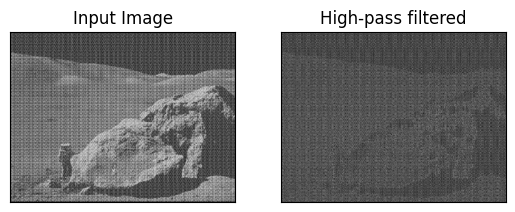

In [ ]:
#task1
rows, cols = img.shape
crow, ccol = rows//2, cols//2

mask_high = np.zeros((rows, cols, 2), np.float32)
sigma = 30
for i in range(rows):
    for j in range(cols):
        d = np.sqrt((i - crow)**2 + (j - ccol)**2)
        mask_high[i, j] = 1 - np.exp(-(d**2) / (2 * sigma**2))

dft_shift_high = dft_shift * mask_high
f_ishift_high = np.fft.ifftshift(dft_shift_high)
img_back_high = cv.idft(f_ishift_high)
img_back_high = cv.magnitude(img_back_high[:,:,0], img_back_high[:,:,1])

plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(img_back_high, cmap = 'gray')
plt.title('High-pass filtered'), plt.xticks([]), plt.yticks([])
plt.show()

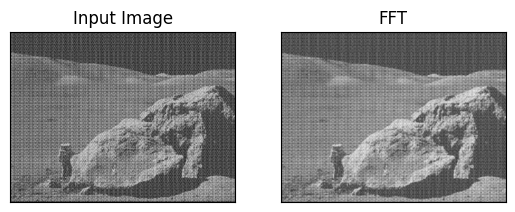

In [4]:
#task2
kernel_size = 5
kernel = cv.getGaussianKernel(kernel_size, 0)
kernel = kernel * kernel.T
kernel_rows, kernel_cols = kernel.shape

rows_pad = rows + kernel_rows - 1
cols_pad = cols + kernel_cols - 1

img_padded = np.pad(img, ((0, kernel_rows-1), (0, kernel_cols-1)), mode='constant')

dft_img = cv.dft(np.float32(img_padded), flags=cv.DFT_COMPLEX_OUTPUT)

kernel_padded = np.zeros((rows_pad, cols_pad), dtype=np.float32)
kernel_padded[:kernel_rows, :kernel_cols] = kernel
kernel_f = cv.dft(np.float32(kernel_padded), flags=cv.DFT_COMPLEX_OUTPUT)

conv_f = cv.mulSpectrums(dft_img, kernel_f, 0)
img_conv = cv.idft(conv_f)
img_conv = cv.magnitude(img_conv[:,:,0], img_conv[:,:,1])

img_conv = img_conv[:rows, :cols]
img_conv = cv.normalize(img_conv, None, 0, 255, cv.NORM_MINMAX)

plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(img_conv, cmap = 'gray')
plt.title('FFT'), plt.xticks([]), plt.yticks([])
plt.show()

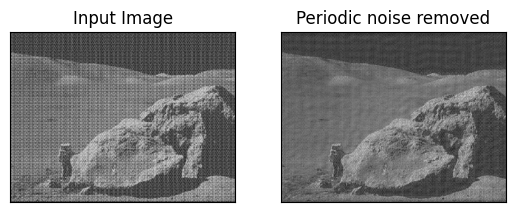

In [5]:
#task3
dft_shift = np.fft.fftshift(dft)

mask_noise = np.ones((rows, cols, 2), np.float32)

dft_mag = cv.magnitude(dft_shift[:,:,0], dft_shift[:,:,1])
dft_mag_log = 20*np.log(dft_mag + 1)

threshold = np.percentile(dft_mag_log, 99.5)
noise_points = np.where(dft_mag_log > threshold)

for i, j in zip(noise_points[0], noise_points[1]):
    dist_from_center = np.sqrt((i - crow)**2 + (j - ccol)**2)
    if dist_from_center > 20:
        mask_noise[i, j] = 0
        i_sym = rows - 1 - i
        j_sym = cols - 1 - j
        mask_noise[i_sym, j_sym] = 0

dft_shift_clean = dft_shift * mask_noise
f_ishift_clean = np.fft.ifftshift(dft_shift_clean)
img_clean = cv.idft(f_ishift_clean)
img_clean = cv.magnitude(img_clean[:,:,0], img_clean[:,:,1])
img_clean = cv.normalize(img_clean, None, 0, 255, cv.NORM_MINMAX)

plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(img_clean, cmap = 'gray')
plt.title('Periodic noise removed'), plt.xticks([]), plt.yticks([])
plt.show()